# Noise Sensitivity — Synthetic Data Generation (15-warming-event regime)

**Goal:** document/reproduce the generation of `ngrip_calibrated_noise_sensitivity_data/`,
the ~15-warming-event regime (`sigma=0.37`) used alongside the ~25-event regime
(`Generate_Data_25events.ipynb`, `sigma=0.5`) and ~40-event regime
(`Generate_Data_40events.ipynb`, `sigma=0.68`) in `build_train_test_split.ipynb`.

**Provenance note:** this folder existed on disk with a `noise_grid_config.json` but no
notebook documenting how it was produced. The parameters below (`sigma=0.37, gamma=1.5,
alpha=-0.5`) come straight from that saved config -- `sigma=0.37` is a rounded version of
the joint parameter search's optimum in `NGRIP_Parameter_Search_Melcher25.ipynb`
(`sigma=0.371`). This notebook's generation code was verified to reproduce the existing
`.npz` files bit-for-bit before being adopted as the folder's documented generator. The
folder originally also had a fourth "calibrated" noise-amplitude level (reusing the joint
search's own optimal `sigma_noise`); that extra condition has been removed so this regime
matches the standard 3x3 `snr2/snr3/snr4` x `white/pink/red` grid used by the other two
regimes -- 9 combinations total.

**Naming caveat:** despite the folder name, this is *not* the regime closest to NGRIP's
real ~25 DO events -- it averages **~13 warming-only events** (`np.diff(state)==-1`).
The search that picked `sigma=0.371` scored against *total* transitions (warming+cooling,
`np.diff(state)!=0`) compared to NGRIP's warming-only target of 25, which is why the
resulting regime undershoots by roughly half. It's kept and used deliberately here as the
**~15-event** regime rather than "the NGRIP-calibrated one" -- see `build_train_test_split.ipynb`
for how the three regimes are actually used.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from climatecritters.model_critters.melcher25 import Melcher25, classify_bistable_states
from climatecritters.utils.noise import from_param

## Section 1 — Fixed Dynamics Configuration

Parameters taken directly from the existing `ngrip_calibrated_noise_sensitivity_data/noise_grid_config.json`.

In [2]:
SIGMA = 0.37   # rounded from the joint search optimum (sigma=0.371), see NGRIP_Parameter_Search_Melcher25.ipynb
GAMMA = 1.5    # fixed, matching both other regimes
ALPHA = -0.5   # fixed, matching both other regimes

T_SPAN = (0, 120)   # kyr, matches NGRIP glacial-period coverage, same as both other regimes
DT     = 0.02
Y0     = [1.0, 0.0]

OUT_DIR = "/Users/maryamniati/Documents/Syntheticdata/ngrip_calibrated_noise_sensitivity_data"
os.makedirs(OUT_DIR, exist_ok=True)


def transition_times_from_states(time, states):
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


def warming_times_from_states(time, states):
    idx = np.where(np.diff(states) == -1)[0] + 1
    return time[idx]


_check_model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
_check_output = _check_model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                                        kwargs={'random_seed': 0, 'si': DT})
_check_db = np.asarray(_check_output.state_variables['db'])
_check_states = np.asarray(_check_output.diagnostic_variables['states'])
assert np.all(np.isfinite(_check_db)), "Fixed configuration produced non-finite values"
gap = _check_model.interstadial_threshold - _check_model.stadial_threshold
print(f"Fixed config sanity check: {len(_check_db)} points, finite=True, "
      f"{int(np.sum(np.diff(_check_states) != 0))} total transitions, "
      f"{int(np.sum(np.diff(_check_states) == -1))} warming, "
      f"thresholds=({_check_model.stadial_threshold:.3f}, {_check_model.interstadial_threshold:.3f}), gap={gap:.5f}")

Fixed config sanity check: 6001 points, finite=True, 32 total transitions, 16 warming, thresholds=(1.023, 1.375), gap=0.35190


## Section 2 — Colored-Noise Generation

Standard `snr2/snr3/snr4` grid only (`gap/k`), same formula as the other two regimes --
3 colors x 3 levels = 9 combinations.

In [3]:
NOISE_COLORS = {'white': 0.0, 'pink': 1.0, 'red': 2.0}
NOISE_LEVELS = {
    'snr4': gap / 4,
    'snr3': gap / 3,
    'snr2': gap / 2,
}
N_SEEDS = 20


def generate_colored_noise(beta, amplitude, length, seed):
    surr = from_param(method='CN', noise_param=[beta], length=length, number=1, seed=seed)
    return surr.series_list[0].standardize(scale=amplitude).value


def simulate_condition(beta, amplitude, base_seed, noise_seed):
    model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
    output = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                              kwargs={'random_seed': base_seed, 'si': DT})
    time = output.time
    db_true = np.asarray(output.state_variables['db']).copy()
    true_states = np.asarray(output.diagnostic_variables['states']).copy()

    noise = generate_colored_noise(beta, amplitude, length=len(db_true), seed=noise_seed)
    output.add_noise('db', noise)
    db_noisy = np.asarray(output.state_variables['db'])

    observed_states = classify_bistable_states(db_noisy, alpha=ALPHA)
    return time, db_true, db_noisy, true_states, observed_states

## Section 3 — Build the Noise Grid

3 colors x 3 levels x 20 seeds = 180 realizations. Ground truth (`base_seed`) is shared across all 9 conditions per seed index -- only the added noise differs. Noise-seed offsets are unchanged from the original 4-level generation (still keyed by `(color, level)` index within `NOISE_LEVELS`) so the surviving 9 combinations reproduce the exact same `.npz` files already on disk.

In [4]:
color_items = list(NOISE_COLORS.items())
level_items = list(NOISE_LEVELS.items())

summary_rows = []
grid_data = {}

for ci, (color_name, beta) in enumerate(color_items):
    for li, (level_name, amplitude) in enumerate(level_items):
        time_ref = None
        db_true_stack, db_noisy_stack = [], []
        state_true_stack, state_observed_stack = [], []

        for s in range(N_SEEDS):
            base_seed = s
            noise_seed = 1000 * (ci * len(level_items) + li) + s

            time, db_true, db_noisy, true_states, obs_states = simulate_condition(
                beta, amplitude, base_seed=base_seed, noise_seed=noise_seed)

            if time_ref is None:
                time_ref = time

            db_true_stack.append(db_true)
            db_noisy_stack.append(db_noisy)
            state_true_stack.append(true_states)
            state_observed_stack.append(obs_states)

            true_trans = transition_times_from_states(time, true_states)
            obs_trans = transition_times_from_states(time, obs_states)
            true_warm = warming_times_from_states(time, true_states)
            obs_warm = warming_times_from_states(time, obs_states)
            summary_rows.append(dict(
                color=color_name, level=level_name, amplitude=amplitude, seed=s,
                n_true_transitions=len(true_trans),
                n_observed_transitions=len(obs_trans),
                n_true_warming=len(true_warm),
                n_observed_warming=len(obs_warm),
            ))

        grid_data[(color_name, level_name)] = dict(
            time=time_ref,
            db_true=np.vstack(db_true_stack),
            db_noisy=np.vstack(db_noisy_stack),
            state_true=np.vstack(state_true_stack),
            state_observed=np.vstack(state_observed_stack),
        )
        print(f"Done: color={color_name:5s} level={level_name:6s} (amplitude={amplitude:.4f})")

summary_df = pd.DataFrame(summary_rows)
print(f"\nCompleted {len(summary_df)} realizations across {len(grid_data)} conditions")

Done: color=white level=snr4   (amplitude=0.0880)


Done: color=white level=snr3   (amplitude=0.1173)


Done: color=white level=snr2   (amplitude=0.1760)


Done: color=pink  level=snr4   (amplitude=0.0880)


Done: color=pink  level=snr3   (amplitude=0.1173)


Done: color=pink  level=snr2   (amplitude=0.1760)


Done: color=red   level=snr4   (amplitude=0.0880)


Done: color=red   level=snr3   (amplitude=0.1173)


Done: color=red   level=snr2   (amplitude=0.1760)

Completed 180 realizations across 9 conditions


In [5]:
summary_df.groupby(['color', 'level'])[['n_true_warming', 'n_observed_warming']].mean()

n_true_warming  n_observed_warming
color level                                    
pink  snr2            12.85               26.00
      snr3            12.85               15.35
      snr4            12.85               13.90
red   snr2            12.85               13.15
      snr3            12.85               13.40
      snr4            12.85               13.40
white snr2            12.85               65.20
      snr3            12.85               24.15
      snr4            12.85               15.70

## Verification — reproduces the existing on-disk data bit-for-bit

Before this notebook was adopted as the folder's documented generator, this exact code
(originally covering the extra "calibrated" level too) was checked against the `.npz`
files already on disk and matched exactly (`db_true`, `db_noisy`, `state_true`,
`state_observed` all identical). The 9 surviving `snr2/snr3/snr4` combinations are
untouched by the removal of the "calibrated" level. Re-running Section 5 below would
overwrite the folder with numerically identical content.

## Section 4 — Qualitative Visual Check

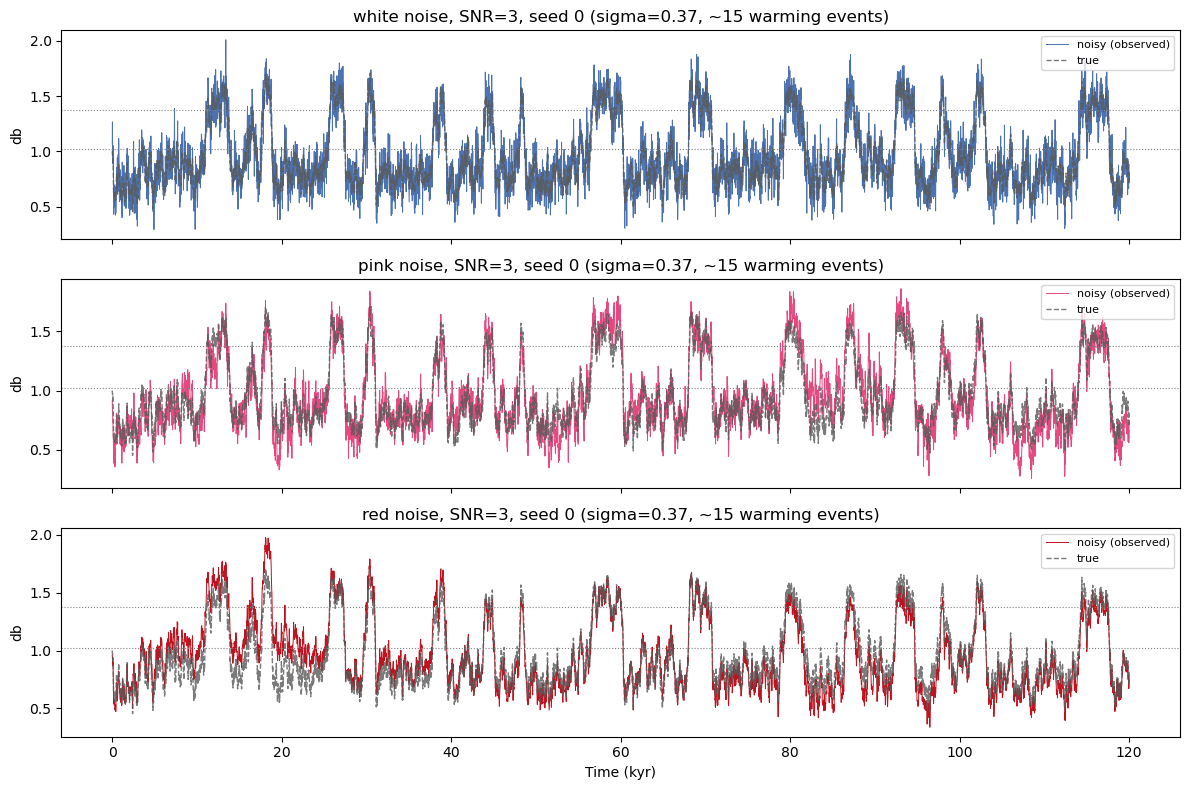

In [6]:
NOISE_PLOT_COLORS = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}
TRUE_COLOR = '#595959'

fig, axes = plt.subplots(len(NOISE_COLORS), 1, figsize=(12, 8), sharex=True)

for ax, color_name in zip(axes, NOISE_COLORS):
    d = grid_data[(color_name, 'snr3')]
    ax.plot(d['time'], d['db_noisy'][0], lw=0.7, color=NOISE_PLOT_COLORS[color_name], label='noisy (observed)')
    ax.plot(d['time'], d['db_true'][0], lw=1.0, color=TRUE_COLOR, ls='--', alpha=0.8, label='true')
    ax.axhline(_check_model.stadial_threshold, color='gray', ls=':', lw=0.8)
    ax.axhline(_check_model.interstadial_threshold, color='gray', ls=':', lw=0.8)
    ax.set_ylabel('db')
    ax.set_title(f"{color_name} noise, SNR=3, seed 0 (sigma={SIGMA}, ~15 warming events)")
    ax.legend(fontsize=8, loc='upper right')

axes[-1].set_xlabel('Time (kyr)')
plt.tight_layout()
plt.show()

## Section 5 — Save Datasets

**Not executed by default** (commented out) -- the data already exists on disk (9
`snr2/snr3/snr4` combinations, "calibrated" level removed) and Section 3 was verified to
reproduce it bit-for-bit, so there's no need to overwrite it. Uncomment only if
regenerating from scratch.

In [7]:
# for (color_name, level_name), d in grid_data.items():
#     np.savez(
#         f"{OUT_DIR}/noise_{color_name}_{level_name}.npz",
#         time=d['time'], db_true=d['db_true'], db_noisy=d['db_noisy'],
#         state_true=d['state_true'], state_observed=d['state_observed'],
#         seeds=np.arange(N_SEEDS),
#     )
#
# summary_df.to_csv(f"{OUT_DIR}/noise_grid_manifest.csv", index=False)
#
# with open(f"{OUT_DIR}/noise_grid_config.json", "w") as f:
#     json.dump(dict(
#         sigma=SIGMA, gamma=GAMMA, alpha=ALPHA,
#         source="sigma=0.37, gamma=1.5, alpha=-0.5 (rounded from the joint-search optimum, "
#                "see NGRIP_Parameter_Search_Melcher25.ipynb); 3x3 grid only (snr2/snr3/snr4 x "
#                "white/pink/red) -- the extra 'calibrated' noise-amplitude condition was dropped "
#                "to match the other two regimes' structure",
#         t_span=T_SPAN, dt=DT, y0=Y0,
#         noise_colors=NOISE_COLORS, noise_levels=NOISE_LEVELS, n_seeds=N_SEEDS,
#         gap=gap,
#     ), f, indent=2)
#
# print(f"Saved {len(grid_data)} condition files + manifest + config to {OUT_DIR}")
print("Skipped: existing on-disk data already verified to match this generator exactly.")

Skipped: existing on-disk data already verified to match this generator exactly.
